<a href="https://colab.research.google.com/github/MuhammadUmar654/Datacamp_exam_sample/blob/main/Datacamp_exam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Core business question:

Over the past quarter, we’ve seen big differences in ancillary revenue (spa, dining, and
activities) across our guest base. Some guests barely use any of our services, while others
spend a lot — but right now we don’t have a clear view of which types of guests are driving that
revenue or where we might be leaving money on the table.



In [ ]:
#importing necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import auth
from google.cloud import bigquery
%matplotlib inline

In [ ]:

# Authenticate your Colab session with Google Cloud
auth.authenticate_user()
project_id = 'datcamp-sample-exam'
client = bigquery.Client(project=project_id)

stay_details= """
SELECT *
FROM `datcamp-sample-exam.revenue_opel_hotel.stay_details_clean`
"""

stay_details = client.query(stay_details).to_dataframe()
display(stay_details.head())

ancillary_spend= """
SELECT *
FROM `datcamp-sample-exam.revenue_opel_hotel.ancillary_spend_clean`
"""
ancillary_spend = client.query(ancillary_spend).to_dataframe()
display(ancillary_spend.head())

guest_profiles= """
SELECT *
FROM `datcamp-sample-exam.revenue_opel_hotel.guest_profiles`
"""
guest_profiles = client.query(guest_profiles).to_dataframe()
display(guest_profiles.head())



,guest_id,check_in_date,stay_id,booking_channel,reason_for_stay,number_of_guests
0,233,2025-09-06 12:09:35.704163+00:00,446,corporate,business,1
1,150,2025-09-06 12:09:35.704163+00:00,338,corporate,business,1
2,153,2025-09-06 12:09:35.704163+00:00,4,corporate,business,4
3,102,2025-09-07 12:09:35.704163+00:00,445,corporate,business,1
4,235,2025-09-09 12:09:35.704163+00:00,221,corporate,business,2


,amount_spent,guest_id,category
0,578.90,391,Dining
1,373.27,271,Spa
2,352.60,241,Dining
3,343.50,4,Dining
4,335.71,359,Spa


,guest_id,loyalty_tier,marketing_consent
0,13,Gold,False
1,54,Gold,False
2,68,Gold,False
3,74,Gold,False
4,89,Gold,False


We have performed all the necessary data cleaning in Biguqery using SQL. Now we will import data in Collab to perform EDA using python.

We will perform univarate analysis on ancillary spend column since our core Business question revolves around this.

In [ ]:
ancillary_spend.describe()
ancillary_spend['amount_spent'].median()



58.285

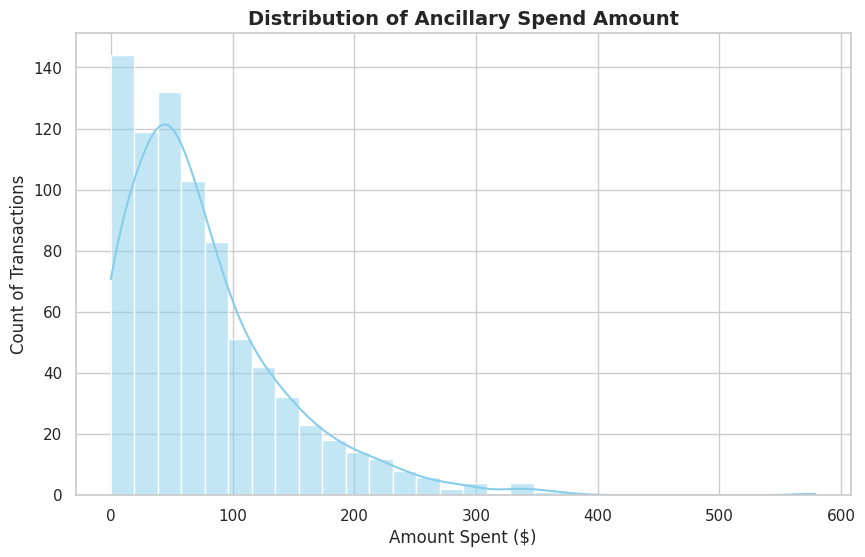

In [ ]:
# Set the plotting style
sns.set_theme(style="whitegrid")

# Create the histogram plot
plt.figure(figsize=(10, 6))
sns.histplot(data=ancillary_spend, x='amount_spent', bins=30, kde=True, color='skyblue')

# Add titles and labels
plt.title('Distribution of Ancillary Spend Amount', fontsize=14, fontweight='bold')
plt.xlabel('Amount Spent ($)', fontsize=12)
plt.ylabel('Count of Transactions', fontsize=12)

# Display the plot
plt.show()



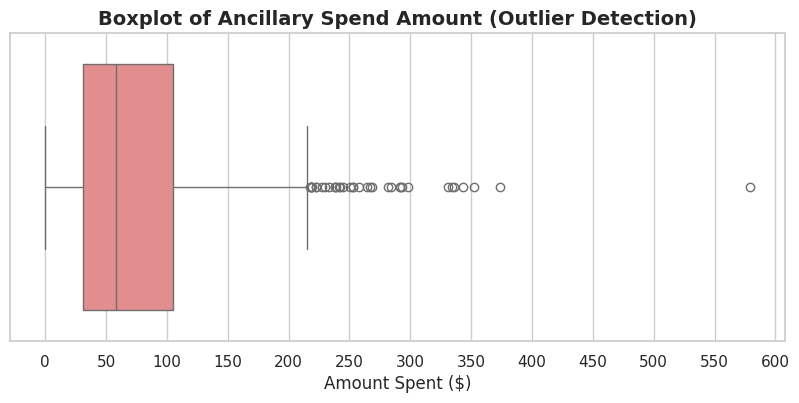

In [ ]:
# Set the plotting style
sns.set_theme(style="whitegrid")

# Create the boxplot
plt.figure(figsize=(10, 4))
sns.boxplot(data=ancillary_spend, x='amount_spent', color='lightcoral')
plt.xticks(np.arange(0, 650, 50))
plt.title('Boxplot of Ancillary Spend Amount (Outlier Detection)', fontsize=14, fontweight='bold')
plt.xlabel('Amount Spent ($)', fontsize=12)
plt.show()

Guest segmentation: Identify which guest types (loyalty tier, business vs. leisure, booking channel) generate the most ancillary revenue.



Spending behaviour: Compare total revenue, average spending per guest, and participation patterns across segments.



Revenue opportunities: Identify valuable segments and potential untapped opportunities.



Category analysis: Examine which services different guest segments spend money on to help explain their behaviour and recommend targeted actions.

In [ ]:
# Calculate total ancillary spend per guest first
guest_spent = ancillary_spend.groupby('guest_id')['amount_spent'].sum().reset_index()
guest_spent['guest_id'] = guest_spent['guest_id'].astype(str)

# Ensure guest_profiles and stay_details guest_id columns are string type
guest_profiles_clean = guest_profiles.copy()
guest_profiles_clean['guest_id'] = guest_profiles_clean['guest_id'].astype(str)

stay_details_clean = stay_details.copy()
stay_details_clean['guest_id'] = stay_details_clean['guest_id'].astype(str)

# Define guest_info before using it
guest_info = pd.merge(guest_spent, guest_profiles_clean, on='guest_id', how='left')

# Define guest_reason correctly using stay_details and the newly defined guest_info
guest_reason = pd.merge(stay_details_clean, guest_info, on='guest_id', how='left')
guest_reason = guest_reason[['guest_id', 'reason_for_stay']]

# Merge everything together
guest_info_reason = pd.merge(guest_info, guest_reason.drop_duplicates(subset=['guest_id']), on='guest_id', how='left')

# Calculate the percentage of spent amount for unknown guests
unknown_guest_spent = guest_info_reason[guest_info_reason['reason_for_stay'].isna()]['amount_spent'].sum() / ancillary_spend['amount_spent'].sum() * 100
unknown_guest_spent

np.float64(8.359418006202256)

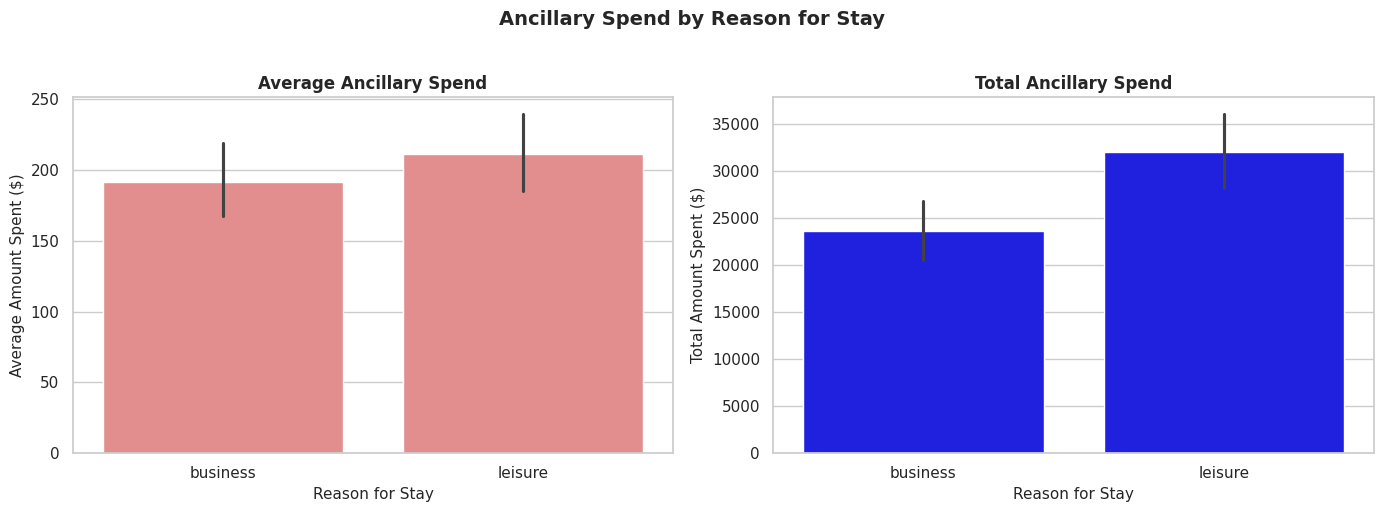

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Create a single figure with 1 row and 2 columns
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: Average Spend (default estimator is mean)
sns.barplot(ax=axes[0], data=guest_info_reason, x='reason_for_stay', y='amount_spent', color='lightcoral')
axes[0].set_title('Average Ancillary Spend', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Reason for Stay', fontsize=11)
axes[0].set_ylabel('Average Amount Spent ($)', fontsize=11)

# Right plot: Total Spend
sns.barplot(ax=axes[1], data=guest_info_reason, x='reason_for_stay', y='amount_spent', color='blue', estimator='sum')
axes[1].set_title('Total Ancillary Spend', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Reason for Stay', fontsize=11)
axes[1].set_ylabel('Total Amount Spent ($)', fontsize=11)

plt.suptitle('Ancillary Spend by Reason for Stay', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# Aggregate guest_info_reason by primary_reason_for_stay
summary_by_reason = (
    guest_info_reason.groupby('reason_for_stay')
    .agg(
        total_amount_spent=('amount_spent', 'sum'),
        avg_amount_spent=('amount_spent', 'mean'),
        guest_count=('guest_id', 'nunique')
    )
    .reset_index()
)

# Display the resulting DataFrame
display(summary_by_reason)

,reason_for_stay,total_amount_spent,avg_amount_spent,guest_count
0,business,23614.53,191.988049,123
1,leisure,31937.89,211.509205,151


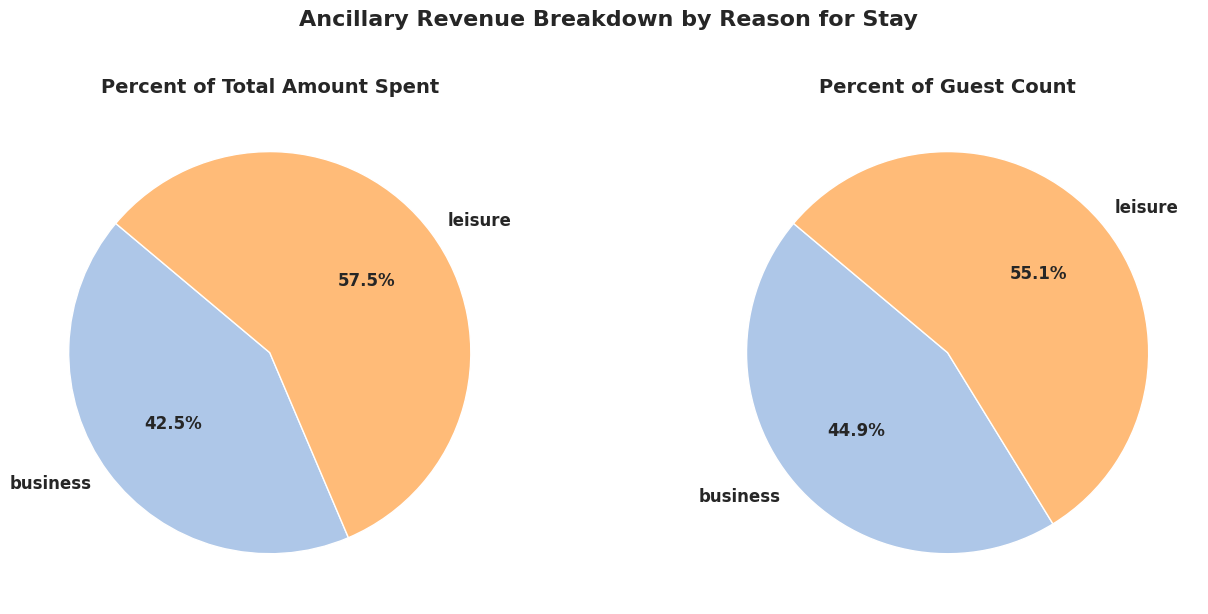

In [ ]:
import matplotlib.pyplot as plt

# Set up the figure with 1 row and 2 columns
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Colors for the segments
colors = ['#aec7e8', '#ffbb78']

# Left Plot: Percent Total Amount Spent
axes[0].pie(
    summary_by_reason['total_amount_spent'],
    labels=summary_by_reason['reason_for_stay'],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)
axes[0].set_title('Percent of Total Amount Spent', fontsize=14, fontweight='bold')

# Right Plot: Percent Guest Count
axes[1].pie(
    summary_by_reason['guest_count'],
    labels=summary_by_reason['reason_for_stay'],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)
axes[1].set_title('Percent of Guest Count', fontsize=14, fontweight='bold')

plt.suptitle('Ancillary Revenue Breakdown by Reason for Stay', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

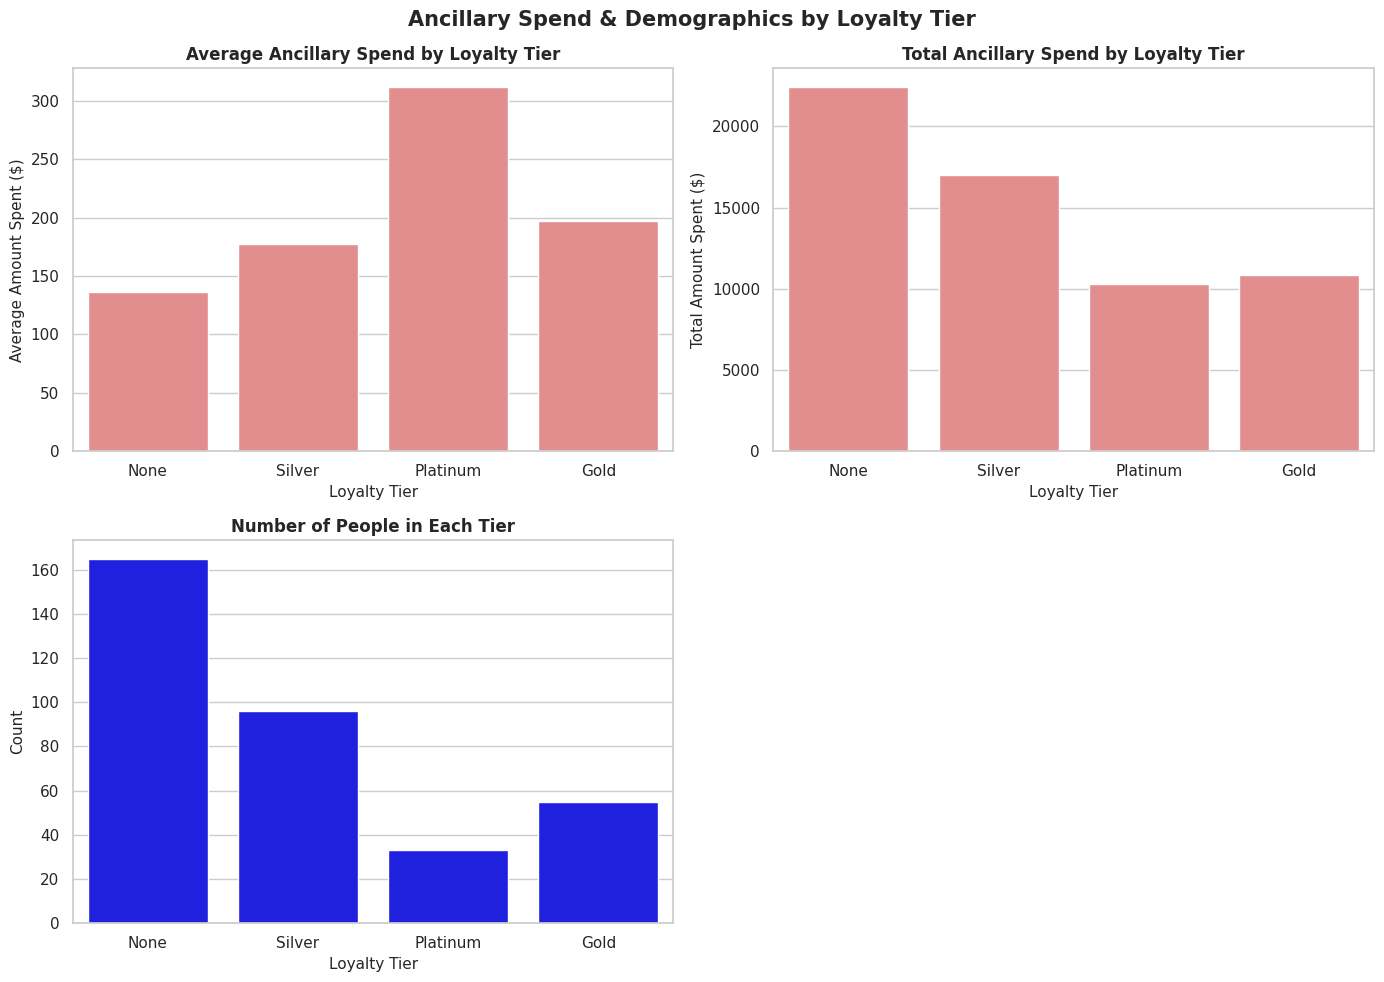

In [ ]:
# Group by guest_id, sum the spent amount, and convert the resulting Series to a DataFrame
guest_spent = ancillary_spend.groupby('guest_id')['amount_spent'].sum().reset_index()
guest_spent['guest_id'] = guest_spent['guest_id'].astype(int)

guest_info = pd.merge(guest_spent, guest_profiles, on='guest_id', how='left')


sns.set_theme(style="whitegrid")

# Create a single figure with a 2x2 grid to arrange three plots
fig = plt.figure(figsize=(14, 10))

# Row 1, Column 1: Average Ancillary Spend
ax1 = plt.subplot2grid((2, 2), (0, 0))
sns.barplot(ax=ax1, data=guest_info, x='loyalty_tier', y='amount_spent', color='lightcoral', errorbar=None)
ax1.set_title('Average Ancillary Spend by Loyalty Tier', fontsize=12, fontweight='bold')
ax1.set_xlabel('Loyalty Tier', fontsize=11)
ax1.set_ylabel('Average Amount Spent ($)', fontsize=11)

# Row 1, Column 2: Total Ancillary Spend
ax2 = plt.subplot2grid((2, 2), (0, 1))
sns.barplot(ax=ax2, data=guest_info, x='loyalty_tier', y='amount_spent', color='lightcoral', estimator='sum', errorbar=None)
ax2.set_title('Total Ancillary Spend by Loyalty Tier', fontsize=12, fontweight='bold')
ax2.set_xlabel('Loyalty Tier', fontsize=11)
ax2.set_ylabel('Total Amount Spent ($)', fontsize=11)

# Row 2, Spanning both columns: Number of people
ax3 = plt.subplot2grid((2, 2), (1, 0), colspan=1)

sns.countplot(ax=ax3, data=guest_info, x='loyalty_tier', color='blue')
ax3.set_title('Number of People in Each Tier', fontsize=12, fontweight='bold')
ax3.set_xlabel('Loyalty Tier', fontsize=11)
ax3.set_ylabel('Count', fontsize=11)

plt.suptitle('Ancillary Spend & Demographics by Loyalty Tier', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

In [ ]:
total_spent_by_tier = guest_info.groupby('loyalty_tier')['amount_spent'].sum().reset_index()
avg_amount_spent_by_tier = guest_info.groupby('loyalty_tier')['amount_spent'].mean().reset_index()
guest_count_by_tier = guest_info.groupby('loyalty_tier')['guest_id'].nunique().reset_index()

# Findings:
* Guests without a loyalty tier contribute the most total ancillary revenue because of a higher number
* Leisure travellers contribute more ancillary revenue than business travellers.
* Guests with a premium loyalty tier spend more on average but almost 50% dont fall in any loyalty tier

### Futher Analysis:

We have identified tha above pattern in spending behaviours of different type of guests we will do further anlaysis to to find out which subgroup actually spends the most. For example, we cannot assume that leisure travellers without a loyalty tier are the highest-revenue subgroup simply because each category leads independently.

Final Question:

* Total ancillary revenue — which subgroup contributes the most?
* Average spending per purchasing guest — which subgroup spends the most individually
* Number of purchasing guests — is the subgroup's revenue driven by volume or spending intensity?







# Why we are not using booking-channel segmentation
We discovered that 40.1% of guests in stay_details used multiple booking channels.

Because ancillary transactions cannot reliably be attributed to individual stays, we cannot confidently assign each guest's historical ancillary revenue to a particular booking channel.

Therefore, we cannot make a claim such as "website bookings generated the most ancillary revenue" without a defensible attribution method.


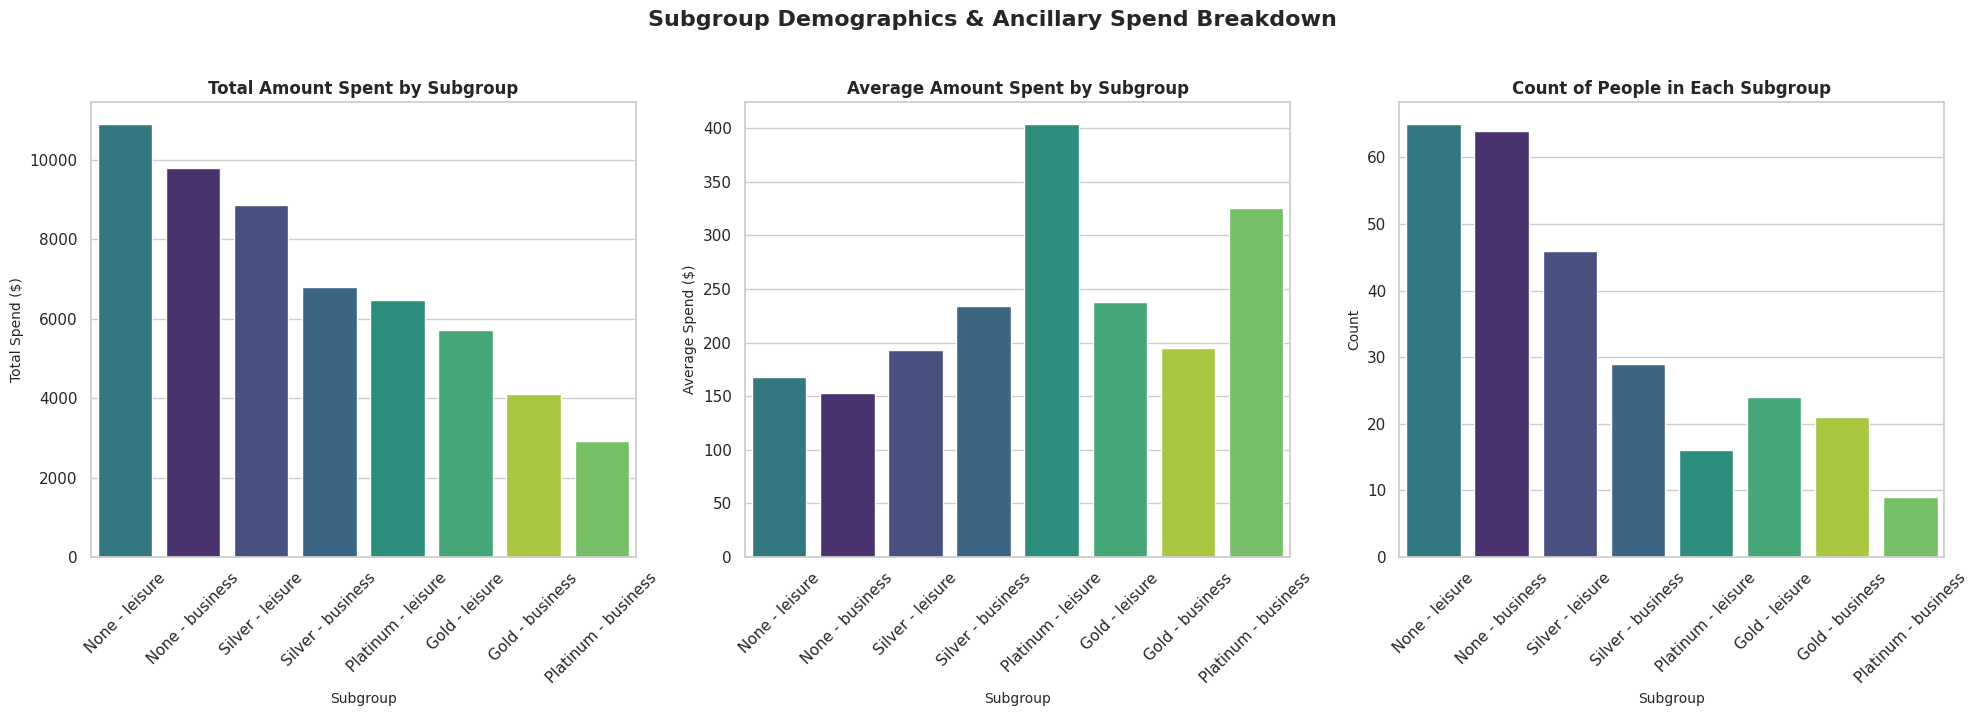

In [ ]:
# Ensure both guest_id columns are string type to prevent merge type conflicts
guest_info_clean = guest_info.copy()
guest_info_clean['guest_id'] = guest_info_clean['guest_id'].astype(str)

guest_reason_clean = guest_reason.copy()
guest_reason_clean['guest_id'] = guest_reason_clean['guest_id'].astype(str)

# Merge reason_for_stay into guest_info to get the full profile
guest_info_merged = pd.merge(guest_info_clean, guest_reason_clean.drop_duplicates(subset=['guest_id']), on='guest_id', how='left')

# Combine loyalty_tier and reason_for_stay into a single variable for plotting
guest_info_merged['subgroup'] = guest_info_merged['loyalty_tier'].astype(str) + " - " + guest_info_merged['reason_for_stay'].astype(str)

# Filter out NaN subgroups to focus on valid categories
guest_info_filtered = guest_info_merged.dropna(subset=['reason_for_stay'])

# Calculate sorted order based on total amount spent (highest to lowest)
sorted_order = (
    guest_info_filtered.groupby('subgroup')['amount_spent']
    .sum()
    .sort_values(ascending=False)
    .index.tolist()
)

# Set the plotting style
sns.set_theme(style="whitegrid")

# Create a single canvas with 1 row and 3 columns
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# 1. Left Plot: Total Spend
sns.barplot(
    ax=axes[0],
    data=guest_info_filtered,
    x='subgroup',
    y='amount_spent',
    errorbar=None,
    hue='subgroup',
    palette='viridis',
    estimator='sum',
    legend=False,
    order=sorted_order
)
axes[0].set_title('Total Amount Spent by Subgroup', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Subgroup', fontsize=10)
axes[0].set_ylabel('Total Spend ($)', fontsize=10)
axes[0].tick_params(axis='x', rotation=45)

# 2. Middle Plot: Average Spend
sns.barplot(
    ax=axes[1],
    data=guest_info_filtered,
    x='subgroup',
    y='amount_spent',
    errorbar=None,
    hue='subgroup',
    palette='viridis',
    estimator='mean',
    legend=False,
    order=sorted_order
)
axes[1].set_title('Average Amount Spent by Subgroup', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Subgroup', fontsize=10)
axes[1].set_ylabel('Average Spend ($)', fontsize=10)
axes[1].tick_params(axis='x', rotation=45)

# 3. Right Plot: Count of People
sns.countplot(
    ax=axes[2],
    data=guest_info_filtered,
    x='subgroup',
    hue='subgroup',
    palette='viridis',
    legend=False,
    order=sorted_order
)
axes[2].set_title('Count of People in Each Subgroup', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Subgroup', fontsize=10)
axes[2].set_ylabel('Count', fontsize=10)
axes[2].tick_params(axis='x', rotation=45)

plt.suptitle('Subgroup Demographics & Ancillary Spend Breakdown', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Answer to question 1:

**Finding 1 — Highest total revenue**

Leisure travellers with no loyalty tier generate approximately $10,900 in ancillary revenue, making them the largest individual subgroup in your chart.

The relatively large number of purchasing guests (approximately 65) is an important driver of their total revenue.


**Finding 2 — Highest average spendingt**

Platinum leisure travellers spend approximately $400 per purchasing guest, the highest average among the eight subgroups.

**What did we to reach out to conclusion ?**

 * Guest-level revenue aggregation
 * Loyalty-tier comparison
 * Business-versus-leisure comparison
 * Combined guest segmentation
* Identification of the largest and highest-spending segments

**Limitations**

Given the current data we got a defensible answer to the hotel's first business question, with the important limitation that approximately 8% of ancillary revenue couldn't be classified by travel purpose since the guest ids couldn't be found in the stay_details table.


-----------------------------------------------------

# Question 2:

In the first part of the quetion we have identified that which type of guests generate the most revenue for our business moving forward we will identify where the hotel is leaving money on the table by identifying the oppurtunity.

We will use hypothesis testing to find out whether the guests who are associated to a loyalty tier spends because they receive the benefits from their tier to they are just generally high spending users.

# Hyptothesis Testing

Setting our hypothesis,

H₀: There is no positive rank association between loyalty tier and ancillary spending.

H₁: There is a positive rank association between loyalty tier and ancillary spending.

We'll use a significance level of α = 0.05 and a one-sided test, consistent with the directional hypothesis.

**Test type:**

We will use spearmen correatlion test since Loyalty tier is an **ordinal variable** (ranked categories: e.g., Bronze &lt; Silver &lt; Gold &lt; Platinum), and ancillary spending is a **numerical outcome**. Spearman's rank correlation evaluates whether higher ranks in one variable correspond to higher values in another.



In [ ]:
guest_info.head()

,guest_id,amount_spent,loyalty_tier,marketing_consent
0,1,69.45,None,True
1,10,111.53,Silver,True
2,100,0.00,None,False
3,101,553.70,None,True
4,102,427.23,Silver,True


In [ ]:
import scipy.stats as stats

# Map the loyalty tiers to ranks (None=0, Silver=1, Gold=2, Platinum=3)
# To do that we will create a dictionary and then map the dictionary usnig map function

tier_mapping = {
    'None': 0,
    'Silver': 1,
    'Gold': 2,
    'Platinum': 3,
}

# Applying the mapping on the guest info table

guest_info['tier_rank'] = guest_info['loyalty_tier'].map(tier_mapping)

# Calculate Spearman's rank correlation
correlation, p_value = stats.spearmanr(guest_info['tier_rank'], guest_info['amount_spent'], alternative = 'greater')

alpha = 0.05


#print the results

print(f'Spearman correlation coefficient: {correlation:.4f}')
print(f"p-value (one-sided): {p_value:.4e}")



Spearman correlation coefficient: 0.2265
p-value (one-sided): 9.6534e-06


#Results of Hypotheis

We reject our Null Hyp given that the p-value is less then alpha. We can say that there is weak positive correlation between the amount spend and loyalty tier.

In [ ]:
# Find guest profiles that are in guest_profiles but not in guest_info
missing_guests_df = guest_profiles[~guest_profiles['guest_id'].astype(str).isin(guest_info['guest_id'].astype(str))]

# Group by loyalty_tier and show count of guest IDs
missing_by_tier = missing_guests_df.groupby('loyalty_tier')['guest_id'].count().reset_index(name='non_spending_guests')

# Display the counts
display(missing_by_tier)


,loyalty_tier,non_spending_guests
0,Gold,7
1,None,28
2,Platinum,5
3,Silver,11


The number of non spenders in no loyalty tier is the highest, followed by silver, gold and platinum while platinum haveing the lowest number of non spenders. Almost 50 percent of non-spenders come from the guests with no loyalty tier.

In [ ]:
#Finding Potential revenue by assuming the spend from non spenders
#first we will convert our df to a python dictionary so that we can map it using the map() function
tier_avg_spend_map = avg_amount_spent_by_tier.set_index('loyalty_tier')['amount_spent'].to_dict()

#now we will map the dictionary to the amount_spent column in our missig_guest_df
missing_guests_df['potential_spent'] = missing_guests_df['loyalty_tier'].map(tier_avg_spend_map)

#Fiding the non_spending guests who have given us the marketing consent
potential_spending_guests = missing_guests_df[missing_guests_df['marketing_consent'] == True]

/tmp/ipykernel_9204/428800970.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  missing_guests_df['potential_spent'] = missing_guests_df['loyalty_tier'].map(tier_avg_spend_map)


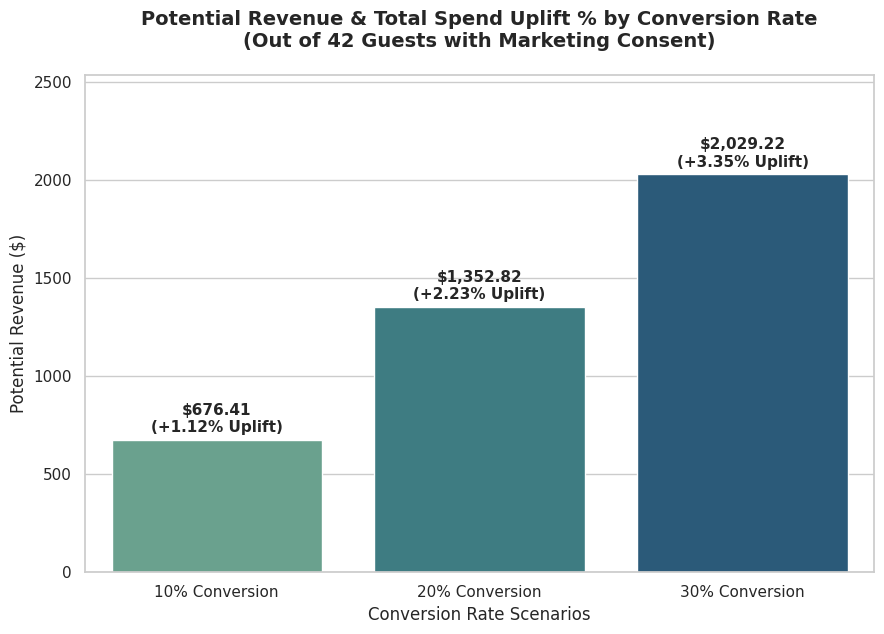

In [ ]:
# Calculate current baseline actual total revenue from ancillary spend
actual_total_revenue = ancillary_spend['amount_spent'].sum()

# Calculate total potential revenue from all 42 guests with marketing consent
total_potential_revenue = potential_spending_guests['potential_spent'].sum()

# Calculate potential revenue for 10%, 20%, and 30% conversion rates
conversion_rates = [0.10, 0.20, 0.30]
scenarios = ['10% Conversion', '20% Conversion', '30% Conversion']
potential_revenues = [total_potential_revenue * rate for rate in conversion_rates]

# Calculate the percentage uplift relative to current actual baseline revenue
uplift_percentages = [(rev / actual_total_revenue) * 100 for rev in potential_revenues]

# Create a DataFrame for plotting
plot_df = pd.DataFrame({
    'Conversion Scenario': scenarios,
    'Potential Revenue ($)': potential_revenues,
    'Uplift %': uplift_percentages
})

# Set the plotting style
sns.set_theme(style="whitegrid")

# Create the bar plot
plt.figure(figsize=(9, 6.5))
ax = sns.barplot(data=plot_df, x='Conversion Scenario', y='Potential Revenue ($)', hue='Conversion Scenario', palette='crest', legend=False)

# Add values and uplift percentages on top of the bars
for i, p in enumerate(ax.patches):
    height = p.get_height()
    uplift_val = plot_df.loc[i, 'Uplift %']
    ax.annotate(f"${height:,.2f}\n(+{uplift_val:.2f}% Uplift)",
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='center',
                xytext=(0, 15),
                textcoords='offset points',
                fontsize=11, fontweight='bold')

# Set labels and title
plt.title('Potential Revenue & Total Spend Uplift % by Conversion Rate\n(Out of 42 Guests with Marketing Consent)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Conversion Rate Scenarios', fontsize=12)
plt.ylabel('Potential Revenue ($)', fontsize=12)
plt.ylim(0, max(potential_revenues) * 1.25)  # Add extra headroom for the detailed annotations

plt.tight_layout()
plt.show()

## Business KPIs and Baseline Metrics

To evaluate the hotel's progress in increasing ancillary revenue, we recommend monitoring two key performance indicators: **Ancillary Purchase Participation Rate** and **Incremental Ancillary Revenue**.

### KPI 1 — Ancillary Purchase Participation Rate (Primary)

This metric measures the percentage of guests who make at least one recorded ancillary purchase.

**Formula:**

Participation Rate = (Guests with recorded ancillary purchases / Total guests) × 100

**Current baseline:**

- Total guest profiles: 400
- Guests with recorded ancillary spending: 349
- Guests with no recorded ancillary spending: 51
- **Current participation rate: 87.25%**

This indicates that 87.25% of profiled guests have at least one recorded ancillary purchase.

The remaining 12.75% represent a potential opportunity to encourage first-time ancillary purchases.

**Assumption:** Guests without recorded ancillary transactions are treated as non-purchasers for this analysis. Missing transaction records cannot be independently ruled out.

### KPI 2 — Incremental Ancillary Revenue (Secondary)

This metric measures the additional revenue generated as a result of a revenue-growth initiative compared with what would have happened without that initiative.

**Current total ancillary revenue baseline: $60,619.89**

The analysis identified 42 guests with no recorded ancillary spending who have provided marketing consent.

Using spending benchmarks from existing purchasing guests within the same loyalty tiers, we estimated three hypothetical conversion scenarios.

| Assumed conversion rate | Potential additional revenue | Potential revenue uplift |
|---|---:|---:|
| 10% | $676.41 | 1.12% |
| 20% | $1,352.82 | 2.23% |
| 30% | $2,029.22 | 3.35% |

These figures represent illustrative gross-revenue opportunities, not guaranteed increases or observed campaign results.

Actual incremental revenue should ideally be estimated by comparing campaign participants with a randomly assigned control group over the same measurement period. Campaign costs should also be considered when evaluating financial performance.

### Campaign Monitoring

For the proposed campaign targeting the 42 consented guests with no recorded ancillary purchases, management should monitor:

- **Campaign conversion rate:** Percentage of targeted guests who make an ancillary purchase during a defined campaign period.
- **Revenue per eligible guest:** Total ancillary revenue from the campaign population divided by the number of eligible guests, including those who spend nothing.
- **Incremental revenue:** Additional revenue attributable to the campaign, estimated against an appropriate control group.

Because the campaign has not yet been conducted, its post-campaign conversion and incremental revenue baselines cannot be observed from the current dataset. The 10%, 20%, and 30% scenarios provide planning benchmarks rather than historical results.

### Business Recommendation

The hotel should test targeted ancillary-service offers among eligible guests who have no recorded ancillary purchases and have provided marketing consent.

The initial objective should be to increase purchase participation while monitoring whether the initiative produces measurable incremental revenue.

Management should use the pilot results to decide whether the campaign is financially worthwhile and should be expanded.